# Predicting the Adoption of the Light Phone III Using the Bass Diffusion Model

## 1. Introduction

This project analyzes the potential adoption of the Light Phone III,
one of TIME's Best Inventions of 2025.

The objective is to predict how this innovation might spread
among consumers in the United States using the Bass Diffusion Model.

To estimate the model parameters, we use historical smartphone
ownership data from the Pew Research Center.

The analysis focuses on the United States and uses Python
for data processing, parameter estimation, and visualization.

## 2. Similar product

The historical innovation I chose is the smartphone because it is similar to the Light Phone III. Both devices allow people to make calls, send messages, take photos, use maps, and listen to music. The main difference is that the Light Phone III has fewer features because it is designed to help people spend less time on their phones. Both devices use similar technology, such as touchscreens, cameras, and mobile networks. Just as smartphones introduced a new way of using mobile phones, the Light Phone III offers a different approach by focusing on simplicity.

In terms of market impact, both products are influenced by consumer needs, advertising, and social influence. However, traditional smartphones became very popular and are now used by about 91% of U.S. adults, while the Light Phone III is designed for a smaller group of people who want to reduce their screen time. Because of this difference, I use historical smartphone data to estimate how quickly the Light Phone III might spread (parameters p and q). I estimate its potential market size (M) separately because it is unlikely to become as popular as traditional smartphones.


In [161]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from sklearn.metrics import r2_score, mean_squared_error
from datetime import date
import os
os.makedirs("img", exist_ok=True)
os.makedirs("data", exist_ok=True)
os.makedirs("report", exist_ok=True)

## 3. Historical Smartphone Adoption Data

Historical smartphone ownership data for the United States was obtained from the Pew Research Center.

The data shows that smartphone ownership increased from 35% of U.S. adults in 2011 to 91% in 2025.

Smartphone ownership grew quickly during the earlier years, but growth became slower as the market approached saturation.

Our dataset does not include observations for 2017, 2020, and 2022. However, the Bass Model can still be estimated because the calculations use the actual year of each observation.

One limitation is that the data measures the percentage of adults who own smartphones, rather than the total number of people who have adopted smartphones for the first time. Therefore, the Bass Model results should be considered approximate estimates of smartphone diffusion.

In [162]:
data = {
    "Year": [
        2011, 2012, 2013, 2014, 2015,
        2016, 2018, 2019, 2021, 2023,
        2024, 2025],

    "Smartphone_Ownership": [
        35, 46, 56, 59, 69,
        77, 77, 81, 85, 90,
        91, 91]}

df = pd.DataFrame(data)
df

,Year,Smartphone_Ownership
0,2011,35
1,2012,46
2,2013,56
3,2014,59
4,2015,69
5,2016,77
6,2018,77
7,2019,81
8,2021,85
9,2023,90


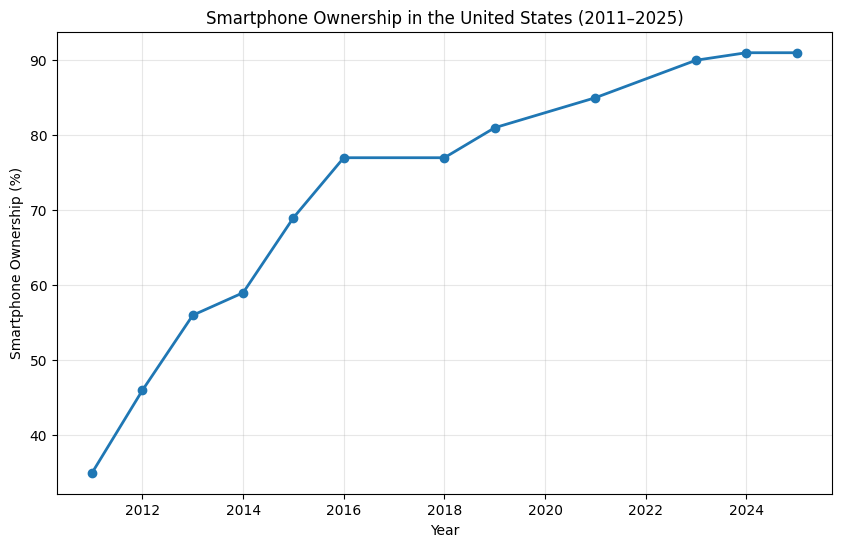

In [163]:
plt.figure(figsize=(10, 6))

plt.plot(
    df["Year"],
    df["Smartphone_Ownership"],
    marker="o",
    linewidth=2)

plt.title("Smartphone Ownership in the United States (2011–2025)")
plt.xlabel("Year")
plt.ylabel("Smartphone Ownership (%)")

plt.grid(True, alpha=0.3)
plt.savefig("img/smartphone_ownership.png", dpi=300, bbox_inches="tight")
plt.show()

In [164]:
df.to_csv("data/smartphone_ownership.csv", index=False)

## 4. Bass Diffusion Model Estimation

The Bass Diffusion Model was used to estimate how smartphones spread in the United States over time.

The model has three main parameters:

* p: Coefficient of innovation
* q: Coefficient of imitation
* M: Market potential

The parameters were estimated using nonlinear least squares with Python's scipy.optimize.curve_fit function.

The year 2007 was chosen as the starting point for the model because the first iPhone was introduced that year. This is an assumption used for the analysis.

Since the historical data measures smartphone ownership rather than the number of first-time adopters, the estimated parameters provide an approximate picture of smartphone diffusion.

The model's accuracy was evaluated using R-squared (R²) and root mean squared error (RMSE).

In [165]:
def bass_model(t, p, q, M):
    numerator = 1 - np.exp(-(p + q) * t)
    denominator = 1 + (q / p) * np.exp(-(p + q) * t)

    return M * numerator / denominator

In [166]:
t = df["Year"].values - 2007
y = df["Smartphone_Ownership"].values

In [167]:
initial_guess = [0.03, 0.4, 100]
params, covariance = curve_fit(
    bass_model,
    t,
    y,
    p0=initial_guess,
    bounds=(
        [0.0001, 0.0001, 0],
        [1, 2, 100]
    ),
    maxfev=10000
)

p, q, M = params

print(f"Coefficient of innovation (p): {p:.4f}")
print(f"Coefficient of imitation (q): {q:.4f}")
print(f"Market potential (M): {M:.2f}%")

Coefficient of innovation (p): 0.0893
Coefficient of imitation (q): 0.1968
Market potential (M): 91.92%


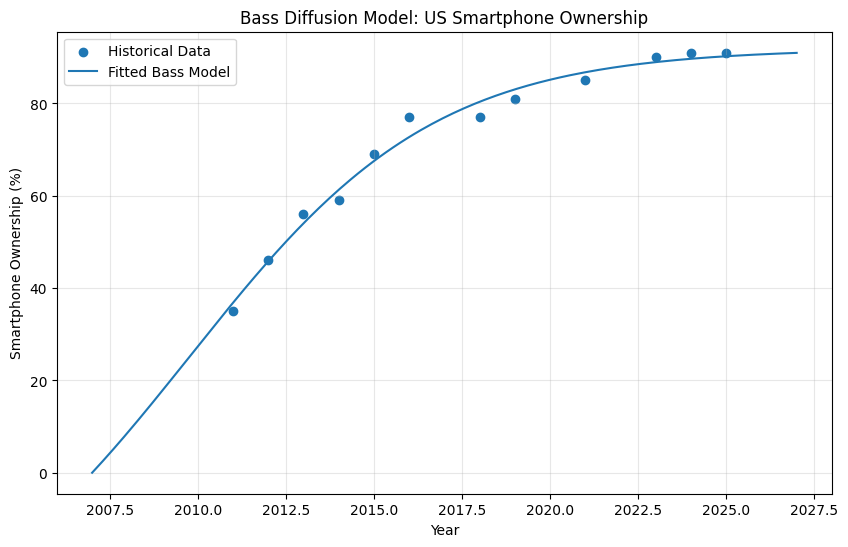

In [168]:
t_pred = np.linspace(0, 20, 200)

y_pred = bass_model(t_pred, p, q, M)

plt.figure(figsize=(10, 6))

plt.scatter(
    df["Year"],
    df["Smartphone_Ownership"],
    label="Historical Data")

plt.plot(
    2007 + t_pred,
    y_pred,
    label="Fitted Bass Model")

plt.title("Bass Diffusion Model: US Smartphone Ownership")
plt.xlabel("Year")
plt.ylabel("Smartphone Ownership (%)")

plt.legend()
plt.grid(True, alpha=0.3)

plt.savefig("img/bass_fit_smartphones.png", dpi=300, bbox_inches="tight")
plt.show()

In [169]:
fitted_values = bass_model(t, p, q, M)
r2 = r2_score(y, fitted_values)
rmse = np.sqrt(mean_squared_error(y, fitted_values))

print(f"R-squared: {r2:.4f}")
print(f"RMSE: {rmse:.4f} percentage points")

R-squared: 0.9856
RMSE: 2.1415 percentage points


In [170]:
std_errors = np.sqrt(np.diag(covariance))

print(f"Standard error of p: {std_errors[0]:.4f}")
print(f"Standard error of q: {std_errors[1]:.4f}")
print(f"Standard error of M: {std_errors[2]:.2f}")

peak_time = np.log(q / p) / (p + q)
print(f"Peak of adoption rate: {peak_time:.2f} years after 2007")

Standard error of p: 0.0133
Standard error of q: 0.0584
Standard error of M: 2.19
Peak of adoption rate: 2.76 years after 2007


## 4.1 Interpretation of the Estimated Parameters

The estimated parameters are:

* Coefficient of innovation (p): 0.0893
* Coefficient of imitation (q): 0.1968
* Market potential (M): 91.92%

The coefficient of imitation is greater than the coefficient of innovation. This suggests that social influence and imitation play an important role in the diffusion process.

The estimated market potential is close to the last observed value of 91%, suggesting that smartphone ownership in the United States is approaching saturation.

The model achieved an R-squared value of 0.9856 and an RMSE of 2.1415 percentage points. The high R-squared indicates that the model fits the historical data well, while RMSE shows the size of the prediction errors.

The model estimates that the adoption rate reached its peak about 2.8 years after 2007, before the first observation in 2011. This means that our dataset mainly covers the period when adoption growth was slowing down. As a result, the estimates of p and q may be less reliable. The standard errors reported above also help show this uncertainty.

For comparison, a meta-analysis of diffusion studies reports average values of approximately p = 0.03 and q = 0.38.

Finally, these parameters were estimated using historical smartphone data. Therefore, they may not accurately describe how consumers will adopt the Light Phone III.

## 5. Scope

The analysis focuses on the United States, adults aged 18+.

- The look-alike data (Pew), the demand data (Pew survey)
  and the population data (U.S. Census Bureau) are all
  measured for the United States.
- Light is based in Brooklyn, New York, and its first
  immediate-delivery channel is a U.S. mobile carrier,
  Noble Mobile.
- A worldwide analysis would need comparable data for each
  country, which is not available.

One limitation is that the number of shipped Light Phone III
devices that we use for calibration is a worldwide number.
Since the reported shipment figure covers worldwide sales, we assume that the United States accounts for 50%, 65%, or 80% of these shipments, depending on the scenario. The real share is not published, so this is an assumption.

## 6. Market Potential Estimation

The market potential is estimated using a Fermi approach and the reported number of Light Phone III shipments.

Step 1: Estimate the potential customer group

* U.S. adults aged 18 and older on July 1, 2025: 269,763,509.
* Percentage of adults who tried to reduce their smartphone use during the previous 12 months: 45%.
* Estimated potential customer group: approximately 121.4 million adults.

This group represents people who may be interested in reducing their smartphone use. However, not everyone in this group would necessarily purchase a minimalist phone.

Step 2: Estimate market potential

There is no reliable data showing what percentage of these consumers would purchase a minimalist phone costing $600 - $800.

Instead of choosing an arbitrary percentage, the market potential (M) is estimated using Light's reported shipments. According to the company, approximately 20,000 Light Phone III devices were shipped worldwide between March 27, 2025, and May 19, 2026 (1.14 years).

Since the analysis focuses on the United States, three scenarios are considered for the U.S. share of worldwide shipments:

* Conservative: 50%
* Base: 65%
* Optimistic: 80%

These percentages are assumptions used to examine different possible market sizes.

The market potential is calculated using:

M = (U.S. share x 20,000) / F(1.14)

where F(t) represents the cumulative adoption share predicted by the Bass Diffusion Model.

The calculation assumes that each shipped device represents one adopter. Since shipments are not necessarily equal to actual adoption, the results should be interpreted as estimates.

Light also reported supply limitations, which may mean that observed shipments were lower than actual consumer demand. Therefore, the estimated market potential may be conservative.

In [171]:
us_adult_population = 269_763_509
share_cut_back = 0.45
shipped_worldwide = 20_000

addressable_group = us_adult_population * share_cut_back
print(f"Addressable group: {addressable_group:,.0f} adults")

t_obs = (date(2026, 5, 19) - date(2025, 3, 27)).days / 365.25

F_obs = bass_model(t_obs, p, q, 1)
print(f"t_obs = {t_obs:.2f} years, F(t_obs) = {F_obs:.4f}")

us_shares = {
    "Conservative": 0.50,
    "Base": 0.65,
    "Optimistic": 0.80}

market_potential = {
    scenario: share * shipped_worldwide / F_obs
    for scenario, share in us_shares.items()}

for scenario, potential in market_potential.items():
    print(f"{scenario}: {potential:,.0f} potential adopters "
          f"({potential / addressable_group:.2%} of the addressable group)")

Addressable group: 121,393,579 adults
t_obs = 1.14 years, F(t_obs) = 0.1079
Conservative: 92,666 potential adopters (0.08% of the addressable group)
Base: 120,466 potential adopters (0.10% of the addressable group)
Optimistic: 148,266 potential adopters (0.12% of the addressable group)


The base scenario gives about 120,466 potential adopters,
which is about 0.1% of the addressable group. This is
consistent with a premium niche product. For comparison,
the earlier Light Phone I and II sold more than 100,000
devices worldwide in about nine years.

## 7. Forecasting the Adoption of the Light Phone III

The Bass Diffusion Model was used to predict how the Light Phone III might spread in the United States between 2025 and 2035.

The parameters estimated from historical smartphone adoption data were used for the forecast:

* p = 0.0893
* q = 0.1968

The forecast starts from March 27, 2025, when the first Light Phone III devices were shipped. The model estimates the total number of adopters at the end of each year. The number of new adopters each year is calculated by finding the difference between the cumulative adopters in two consecutive years. Since the Light Phone III began shipping in March 2025, the adoption estimate for 2025 covers only the period from March 27 to December 31.

These predictions are based on the Bass Model and the estimated market potential under different scenarios. Therefore, they should be considered possible adoption patterns rather than exact predictions of future sales.

In [172]:
years = np.arange(2025, 2036)

start_date = date(2025, 3, 27)

t_future = np.array([
    (date(int(year), 12, 31) - start_date).days / 365.25
    for year in years])

forecast = pd.DataFrame({"Year": years})

for scenario, M_value in market_potential.items():
    forecast[scenario] = bass_model(
        t_future, p, q, M_value)

forecast

,Year,Conservative,Base,Optimistic
0,2025,6567.117287,8537.252473,10507.387660
1,2026,15756.855937,20483.912718,25210.969499
2,2027,25324.169190,32921.419948,40518.670705
3,2028,34916.541491,45391.503939,55866.466386
4,2029,44102.505399,57333.257018,70564.008638
5,2030,52588.095751,68364.524476,84140.953201
6,2031,60150.547822,78195.712169,96240.876515
7,2032,66694.287506,86702.573757,106710.860009
8,2033,72171.399641,93822.819533,115474.239426
9,2034,76663.440913,99662.473187,122661.505460


In [173]:
annual_adoption = pd.DataFrame({"Year": years})

for scenario in market_potential:
    annual_adoption[scenario] = (
        forecast[scenario].diff().fillna(forecast[scenario]))

annual_adoption

,Year,Conservative,Base,Optimistic
0,2025,6567.117287,8537.252473,10507.387660
1,2026,9189.738650,11946.660245,14703.581839
2,2027,9567.313253,12437.507230,15307.701206
3,2028,9592.372301,12470.083991,15347.795681
4,2029,9185.963907,11941.753080,14697.542252
5,2030,8485.590352,11031.267457,13576.944563
6,2031,7562.452071,9831.187693,12099.923314
7,2032,6543.739683,8506.861589,10469.983494
8,2033,5477.112135,7120.245776,8763.379417
9,2034,4492.041272,5839.653653,7187.266035


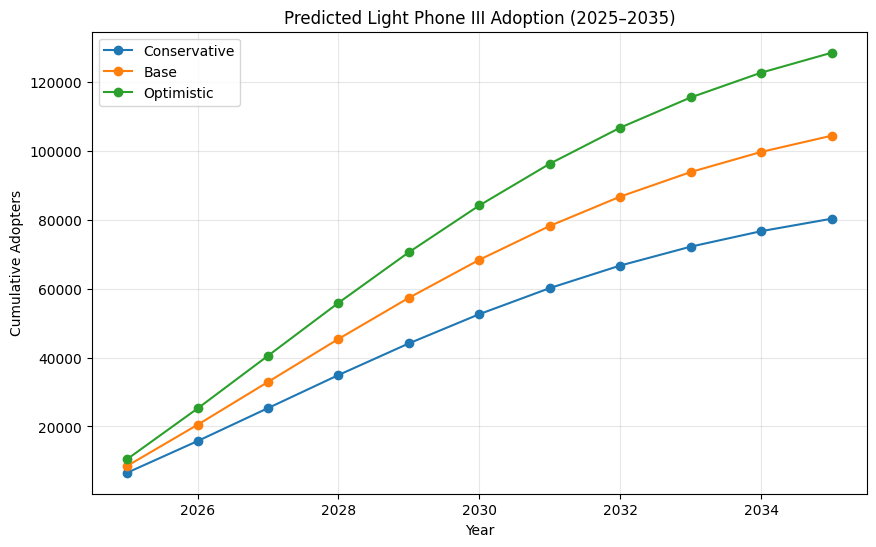

In [174]:
plt.figure(figsize=(10, 6))

for scenario in market_potential:
    plt.plot(
        forecast["Year"],
        forecast[scenario],
        marker="o",
        label=scenario)

plt.title("Predicted Light Phone III Adoption (2025–2035)")
plt.xlabel("Year")
plt.ylabel("Cumulative Adopters")

plt.legend()
plt.grid(True, alpha=0.3)
plt.ticklabel_format(style="plain", axis="y")

plt.savefig("img/cumulative_adoption.png", dpi=300, bbox_inches="tight")
plt.show()

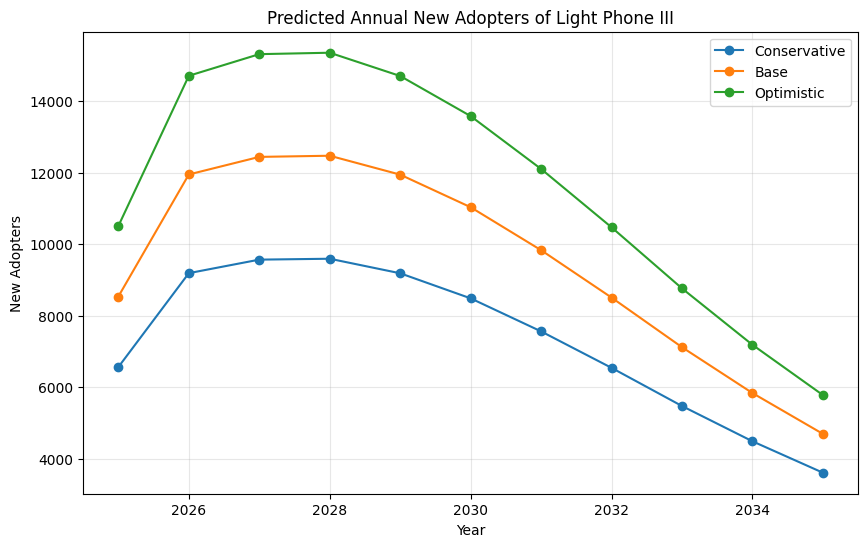

In [175]:
plt.figure(figsize=(10, 6))

for scenario in market_potential:
    plt.plot(
        annual_adoption["Year"],
        annual_adoption[scenario],
        marker="o",
        label=scenario)

plt.title("Predicted Annual New Adopters of Light Phone III")
plt.xlabel("Year")
plt.ylabel("New Adopters")

plt.legend()
plt.grid(True, alpha=0.3)
plt.ticklabel_format(style="plain", axis="y")

plt.savefig("img/annual_adoption.png", dpi=300, bbox_inches="tight")
plt.show()

In [176]:
forecast.to_csv("data/light_phone_cumulative_forecast.csv", index=False)

annual_adoption.to_csv(
    "data/light_phone_annual_forecast.csv",
    index=False)

In [177]:
final_results = pd.DataFrame({
    "Year": years,

    "Conservative_Cumulative": forecast["Conservative"].round(0),
    "Conservative_Annual": annual_adoption["Conservative"].round(0),

    "Base_Cumulative": forecast["Base"].round(0),
    "Base_Annual": annual_adoption["Base"].round(0),

    "Optimistic_Cumulative": forecast["Optimistic"].round(0),
    "Optimistic_Annual": annual_adoption["Optimistic"].round(0)})

display(final_results)

final_results.to_csv(
    "data/light_phone_final_results.csv",
    index=False)

,Year,Conservative_Cumulative,Conservative_Annual,Base_Cumulative,Base_Annual,Optimistic_Cumulative,Optimistic_Annual
0,2025,6567.0,6567.0,8537.0,8537.0,10507.0,10507.0
1,2026,15757.0,9190.0,20484.0,11947.0,25211.0,14704.0
2,2027,25324.0,9567.0,32921.0,12438.0,40519.0,15308.0
3,2028,34917.0,9592.0,45392.0,12470.0,55866.0,15348.0
4,2029,44103.0,9186.0,57333.0,11942.0,70564.0,14698.0
5,2030,52588.0,8486.0,68365.0,11031.0,84141.0,13577.0
6,2031,60151.0,7562.0,78196.0,9831.0,96241.0,12100.0
7,2032,66694.0,6544.0,86703.0,8507.0,106711.0,10470.0
8,2033,72171.0,5477.0,93823.0,7120.0,115474.0,8763.0
9,2034,76663.0,4492.0,99662.0,5840.0,122662.0,7187.0


## 8. Results and Discussion

The Bass Diffusion Model was used to predict the adoption of the Light Phone III in the United States from 2025 to 2035. Under the base scenario, the model predicts approximately 104,000 cumulative adopters by 2035, which represents about 87% of the estimated market potential. The conservative scenario predicts around 80,000 adopters, while the optimistic scenario predicts about 128,000 adopters. These differences are based on the assumed U.S. share of worldwide shipments. The model also predicts that the number of new adopters will increase during the first few years, reaching its highest level in 2028, with approximately 12,470 new adopters in the base scenario. After that, annual adoption gradually decreases as fewer potential customers remain. However, there are some limitations to this analysis. First, the historical parameters were estimated using smartphone ownership data rather than first-time adoption data, which makes the results less certain. Second, the Light Phone III targets a smaller market than traditional smartphones, so its actual adoption may be slower than the model predicts. Third, the estimated market potential depends on one worldwide shipment figure and assumptions about the U.S. share of shipments (50% - 80%). Changes in these assumptions or in the model parameters could affect the predictions. Finally, the model does not consider factors such as competition, pricing, technological changes, or consumer preferences. Therefore, the results should be viewed as possible adoption scenarios rather than exact predictions of future sales.

## 9. Conclusion

This project used the Bass Diffusion Model to predict the adoption of the Light Phone III in the United States from 2025 to 2035. Historical smartphone ownership data from the Pew Research Center was used to estimate the model parameters. The coefficient of innovation was 0.0893, while the coefficient of imitation was 0.1968, suggesting that social influence plays an important role in how new technologies spread. The analysis identified approximately 121.4 million U.S. adults who had tried to reduce their smartphone use as a broad potential customer group. The market potential was then estimated using the reported 20,000 Light Phone III devices shipped by May 2026 and assumptions about the U.S. share of shipments. Under the base scenario, the estimated market potential is about 120,500 U.S. adopters, compared to 92,700 in the conservative scenario and 148,300 in the optimistic scenario. The results suggest that annual adoption will reach its highest level in 2028, while cumulative adoption could reach approximately 104,000 people by 2035 under the base scenario. However, these predictions depend on assumptions about the U.S. share of worldwide shipments and the use of historical smartphone diffusion parameters. Therefore, the results should be considered estimates rather than exact predictions of future adoption.

## 10. References

1. TIME (2025). The Light Phone III.
    ⁠https://time.com/collections/best-inventions-2025/7318280/the-light-phone-iii/
2. TechCrunch (2026). The minimalist Light Phone teams up with Andrew Yang’s Noble Mobile.
    ⁠https://techcrunch.com/2026/05/19/the-minimalist-light-phone-teams-up-with-andrew-yangs-noble-mobile-which-pays-you-to-stop-doomscrolling/
3. Pew Research Center (2025). Mobile Fact Sheet.
    ⁠https://www.pewresearch.org/internet/fact-sheet/mobile/
4. Bass, F. M. (1969). A New Product Growth for Model Consumer Durables.
    ⁠https://doi.org/10.1287/mnsc.15.5.215
5. Apple (2007). Apple Reinvents the Phone with iPhone.
    ⁠https://www.apple.com/newsroom/2007/01/09Apple-Reinvents-the-Phone-with-iPhone/
6. Sultan et al. (1990). A Meta-Analysis of Applications of Diffusion Models.
    ⁠https://doi.org/10.1177/002224379002700107
7. Pew Research Center (2026). About Half of Americans Say They Spend Too Much Time on Their Smartphone.
    ⁠https://www.pewresearch.org/short-reads/2026/09/01/about-half-of-americans-say-they-spend-too-much-time-on-their-smartphone/
8. U.S. Census Bureau (2026). U.S. Adult Population Estimates, 2025.
    ⁠https://www.census.gov/data/datasets/time-series/demo/popest/2020s-state-detail.html